<div align="center">

# 🚗 Used Cars Price Analysis


![Python](https://img.shields.io/badge/Python-3.10+-blue?logo=python&logoColor=white)
![Pandas](https://img.shields.io/badge/Pandas-Data%20Analysis-150458?logo=pandas)
![Plotly](https://img.shields.io/badge/Plotly-Interactive-3F4F75?logo=plotly)
![Scikit-learn](https://img.shields.io/badge/scikit--learn-ML-F7931E?logo=scikitlearn&logoColor=white)

**An end-to-end data analysis and price prediction project on the US used car market**

</div>

<div align="center">
    <img src="https://images.unsplash.com/photo-1492144534655-ae79c964c9d7"
         width="850"
         alt="Luxury Car"/>
</div>

---

## 📌 Project Overview

This project analyzes **5,500 used cars** listed in the US market. The goal is to understand what drives a car's selling price and to build a machine learning model that predicts it.

## 🎯 Business Questions

1. Which factors influence the selling price the most?
2. How fast do cars lose value with age (depreciation)?
3. How much does an accident history reduce the price?
4. Do Electric and Hybrid cars hold their value better?
5. Do color or location have a real effect on price?
6. How accurately can we predict the selling price?

## 📊 Dataset Description

**Size:** 5,500 rows × 18 columns

| Group | Columns | Description |
|---|---|---|
| Identity | `Make`, `Model`, `Year`, `Body_Type`, `Color` | Brand, model name, manufacturing year, body style, color |
| Specs | `Fuel_Type`, `Transmission`, `Engine_Size`, `Horsepower`, `Torque`, `Drivetrain`, `Fuel_Efficiency` | Technical and performance features |
| Condition | `Mileage`, `Owners`, `Accident_History`, `Service_History` | Usage and maintenance history |
| Market | `Location`, `Selling_Price` | US state and the **target variable** (USD) |

**Key data challenges:**
- ~15% missing values across 9 columns (~76% of rows have at least one missing value)
- `Engine_Size = 0` for Electric cars (valid, not an error)
- `Fuel_Efficiency` for Electric cars is on a different scale (MPGe)
- `Selling_Price` is right-skewed → log transformation needed

## 🛠️ Tech Stack

| Purpose | Libraries |
|---|---|
| Data manipulation | `pandas`, `numpy` |
| Static visualization | `matplotlib`, `seaborn` |
| Interactive visualization | `plotly`, `altair` |
| Missing values analysis | `missingno` |
| Machine learning | `scikit-learn`, `xgboost` |
| Model explainability | `shap` |

## 🗺️ Notebook Roadmap

1. **Setup & Data Audit**
2. **Data Cleaning**: missing values, outliers, data types
3. **Exploratory Data Analysis (EDA)**
4. **Feature Engineering**
5. **Modeling & Evaluation**
6. **Insights & Conclusions**

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1)

df = pd.read_csv(r"D:\Codex Ai Course\Codex Training Projects\Python Project\cleaned_cars.csv")
print(df.shape)
df.head()

(5500, 25)


,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,...,Fuel_Efficiency,Location,Selling_Price,Price_Floor,Age,Log_Price,Age_Group,Mileage_per_Year,Is_Luxury,State_Name
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,...,30.0,IL,64140,0,2,11.068839,0-5,50.000000,1,Illinois
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,...,35.0,FL,500,1,18,6.216606,16+,21501.944444,0,Florida
2,Volkswagen,Golf,2021,Hybrid,Automatic,1.9,46054,158.0,153.0,1,...,43.0,NY,16429,0,5,9.706864,0-5,9210.800000,0,New York
3,Chevrolet,Tahoe,2005,Petrol,Automatic,2.2,141302,169.0,165.0,5,...,28.0,FL,2199,0,21,7.696213,16+,6728.666667,0,Florida
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,...,38.0,CA,21792,0,4,9.989344,0-5,8203.250000,0,California


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              5500 non-null   str    
 1   Model             5500 non-null   str    
 2   Year              5500 non-null   int64  
 3   Fuel_Type         5500 non-null   str    
 4   Transmission      5500 non-null   str    
 5   Engine_Size       5500 non-null   float64
 6   Mileage           5500 non-null   int64  
 7   Horsepower        5500 non-null   float64
 8   Torque            5500 non-null   float64
 9   Owners            5500 non-null   int64  
 10  Accident_History  5500 non-null   str    
 11  Service_History   5500 non-null   str    
 12  Color             5500 non-null   str    
 13  Body_Type         5500 non-null   str    
 14  Drivetrain        5500 non-null   str    
 15  Fuel_Efficiency   5500 non-null   float64
 16  Location          5500 non-null   str    
 17  Sellin

In [3]:
df.describe()

,Year,Engine_Size,Mileage,Horsepower,Torque,Owners,Fuel_Efficiency,Selling_Price,Price_Floor,Age,Log_Price,Mileage_per_Year,Is_Luxury
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,2014.494000,2.454382,114529.481636,198.855455,189.284727,2.464000,34.081364,12319.873636,0.221091,11.506000,8.603148,8906.370276,0.289273
std,5.789745,0.827887,91858.943421,54.943175,55.525093,1.280022,14.781240,12658.478862,0.415019,5.789745,1.536670,5033.845404,0.453466
min,2005.000000,0.000000,100.000000,97.000000,77.000000,1.000000,10.000000,500.000000,0.000000,2.000000,6.216606,4.761905,0.000000
25%,2009.000000,2.000000,39112.000000,158.500000,150.000000,1.000000,28.000000,1304.750000,0.000000,6.000000,7.174531,5305.122294,0.000000
50%,2014.000000,2.400000,96926.500000,189.000000,180.000000,2.000000,32.000000,8586.000000,0.000000,12.000000,9.058005,8963.500000,0.000000
75%,2020.000000,2.900000,172757.500000,227.000000,215.000000,3.000000,36.000000,19097.500000,0.000000,17.000000,9.857365,12440.819805,1.000000
max,2024.000000,5.700000,536731.000000,434.000000,443.000000,5.000000,141.000000,86692.000000,1.000000,21.000000,11.370128,26148.333333,1.000000


## 🎯 Target and Features

- **Target:** `Log_Price` (log-transformed price, less skewed). Predictions are converted back to dollars for evaluation.
- **Dropped to avoid data leakage:** `Selling_Price` and `Log_Price` (the target itself) and `Price_Floor` (it is computed directly from the price).
- **Dropped as redundant:** `Year` (same information as `Age`), `Age_Group` (derived from `Age`), `State_Name` (same as `Location`).

Target & Features

In [4]:
y = df["Log_Price"]

drop_cols = ["Selling_Price", "Log_Price", "Price_Floor",
             "Year", "Age_Group", "State_Name"]
X = df.drop(columns=drop_cols, errors="ignore")

print("Features used:", X.columns.tolist())
print("Number of features:", X.shape[1])

Features used: ['Make', 'Model', 'Fuel_Type', 'Transmission', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Accident_History', 'Service_History', 'Color', 'Body_Type', 'Drivetrain', 'Fuel_Efficiency', 'Location', 'Age', 'Mileage_per_Year', 'Is_Luxury']
Number of features: 19


Train/Test

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=df["Price_Floor"]      # keep the same share of $500 cars in both sets
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (4400, 19) | Test: (1100, 19)


Preprocessing Pipeline

In [6]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
])

print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['Make', 'Model', 'Fuel_Type', 'Transmission', 'Accident_History', 'Service_History', 'Color', 'Body_Type', 'Drivetrain', 'Location']
Numeric: ['Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Fuel_Efficiency', 'Age', 'Mileage_per_Year', 'Is_Luxury']


Baseline

In [7]:
def evaluate(model, name):
    pred_log = model.predict(X_test)
    pred = np.clip(np.expm1(pred_log), 500, None)   # price can't go below the $500 floor
    true = np.expm1(y_test)
    metrics = {
        "Model": name,
        "R2 (log)": round(r2_score(y_test, pred_log), 3),
        "R2 ($)": round(r2_score(true, pred), 3),
        "MAE ($)": round(mean_absolute_error(true, pred)),
        "RMSE ($)": round(np.sqrt(mean_squared_error(true, pred))),
    }
    return metrics, pred, true

lr = Pipeline([("prep", preprocess), ("model", LinearRegression())])
lr.fit(X_train, y_train)

lr_metrics, lr_pred, lr_true = evaluate(lr, "Linear Regression")
results = [lr_metrics]
pd.DataFrame(results)

,Model,R2 (log),R2 ($),MAE ($),RMSE ($)
0,Linear Regression,0.919,0.736,3046,6609


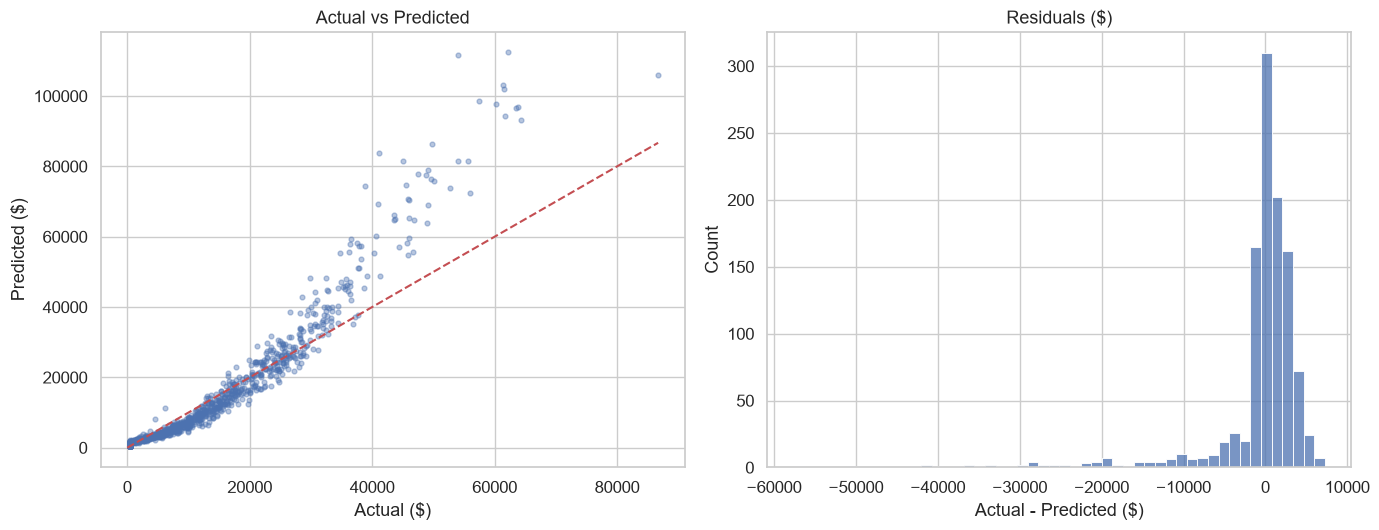

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

ax[0].scatter(lr_true, lr_pred, alpha=0.4, s=12)
lim = [0, lr_true.max()]
ax[0].plot(lim, lim, "r--")
ax[0].set_title("Actual vs Predicted")
ax[0].set_xlabel("Actual ($)")
ax[0].set_ylabel("Predicted ($)")

residuals = (lr_true - lr_pred).values
sns.histplot(residuals, bins=50, ax=ax[1])
ax[1].set_title("Residuals ($)")
ax[1].set_xlabel("Actual - Predicted ($)")

plt.tight_layout()
plt.show()

### Baseline conclusion
- Linear Regression reaches **R² = 0.919** on the log scale but only **0.736** in dollars.
- The model **over-predicts expensive cars** (points curve above the diagonal), because it assumes purely additive effects.
- This motivates tree-based models, which capture interactions between age, brand, and condition.

## 🌲 Advanced Models

Linear Regression over-predicted expensive cars. Tree-based models can capture
interactions (age × brand × condition), so we train **Random Forest** and **XGBoost**
and compare all three on the same test set.

In [9]:
# If xgboost is missing:  pip install xgboost
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8,
                            random_state=42, n_jobs=-1),
}

results, fitted, preds = [], {}, {}
for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)]).fit(X_train, y_train)
    metrics, pred, true = evaluate(pipe, name)
    results.append(metrics)
    fitted[name], preds[name] = pipe, pred

results_df = pd.DataFrame(results).sort_values("MAE ($)").reset_index(drop=True)
results_df

,Model,R2 (log),R2 ($),MAE ($),RMSE ($)
0,XGBoost,0.984,0.984,918,1641
1,Random Forest,0.971,0.962,1542,2502
2,Linear Regression,0.919,0.736,3046,6609


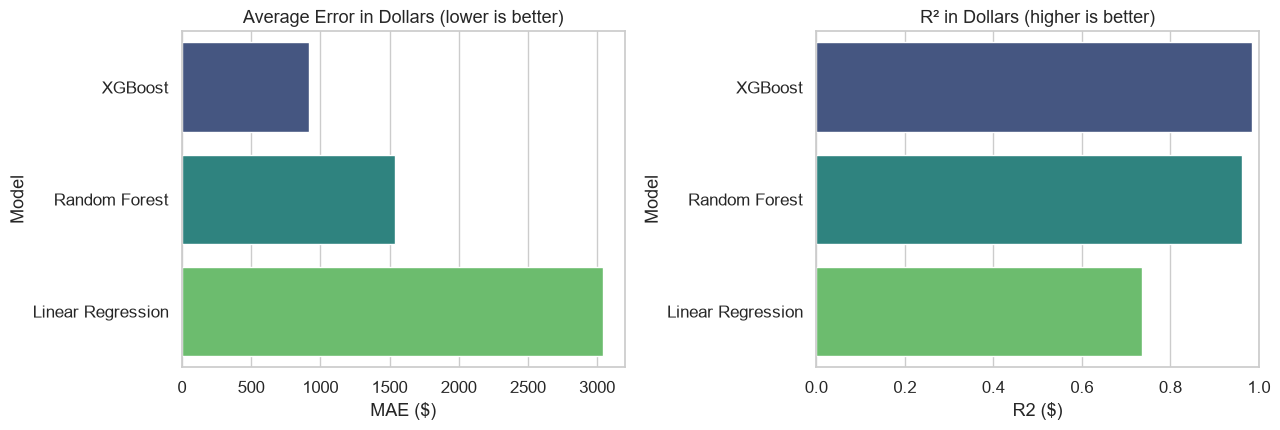

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=results_df, x="MAE ($)", y="Model", hue="Model",
            palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Average Error in Dollars (lower is better)")

sns.barplot(data=results_df, x="R2 ($)", y="Model", hue="Model",
            palette="viridis", legend=False, ax=ax[1])
ax[1].set_xlim(0, 1)
ax[1].set_title("R² in Dollars (higher is better)")

plt.tight_layout()
plt.show()

Actual vs Predicted

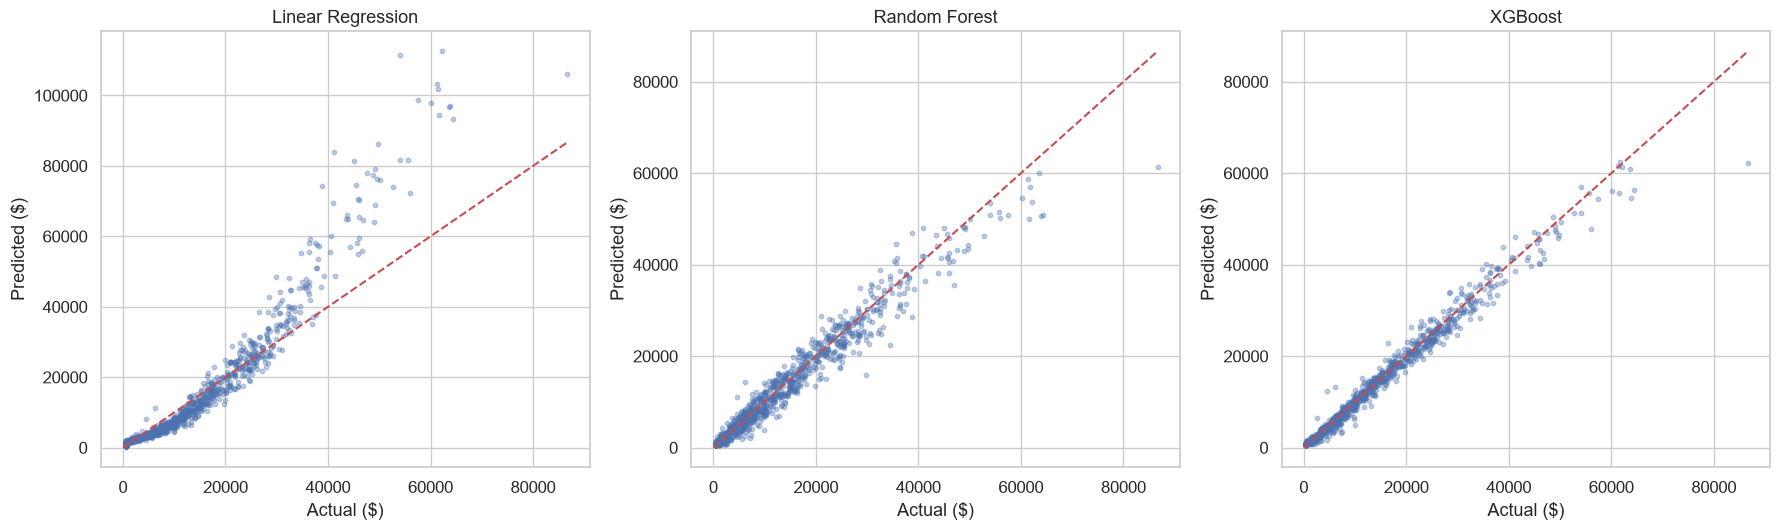

In [11]:
true = np.expm1(y_test)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, name in zip(ax, ["Linear Regression", "Random Forest", "XGBoost"]):
    a.scatter(true, preds[name], alpha=0.35, s=10)
    a.plot([0, true.max()], [0, true.max()], "r--")
    a.set_title(name)
    a.set_xlabel("Actual ($)")
    a.set_ylabel("Predicted ($)")
plt.tight_layout()
plt.show()

Overfitting + Cross-Validation

In [12]:
from sklearn.model_selection import cross_val_score, KFold

for name in ["Random Forest", "XGBoost"]:
    tr = r2_score(y_train, fitted[name].predict(X_train))
    te = r2_score(y_test, fitted[name].predict(X_test))
    print(f"{name:14s} train R2 = {tr:.3f} | test R2 = {te:.3f}")

xgb_pipe = Pipeline([("prep", preprocess), ("model", models["XGBoost"])])
cv = cross_val_score(xgb_pipe, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
print("\nXGBoost 5-fold CV R2:", cv.round(3))
print(f"Mean = {cv.mean():.3f}  |  Std = {cv.std():.3f}")

Random Forest  train R2 = 0.996 | test R2 = 0.971
XGBoost        train R2 = 0.996 | test R2 = 0.984

XGBoost 5-fold CV R2: [0.982 0.984 0.986 0.984 0.983]
Mean = 0.984  |  Std = 0.001


In [13]:
best_name = results_df.iloc[0]["Model"]
best_pred = preds[best_name]
true_vals = true.values

bins = pd.cut(true_vals, [0, 5000, 15000, 30000, 100000],
              labels=["<5k", "5-15k", "15-30k", "30k+"])

err = pd.DataFrame({
    "Abs_Error": np.abs(true_vals - best_pred),
    "Pct_Error": np.abs(true_vals - best_pred) / true_vals * 100,
    "Price_Range": bins,
})
err.groupby("Price_Range", observed=True).agg(
    MAE=("Abs_Error", "mean"), MAPE_pct=("Pct_Error", "mean"), Cars=("Abs_Error", "size")
).round(1)

,MAE,MAPE_pct,Cars
Price_Range,,,
<5k,272.3,19.2,416
5-15k,866.1,9.8,313
15-30k,1342.3,6.2,263
30k+,2518.1,6.0,108


## ✅ Modeling Summary

| Model | R² (log) | R² ($) | MAE ($) | RMSE ($) |
|---|---|---|---|---|
| **XGBoost** | **0.984** | **0.984** | **913** | **1,639** |
| Random Forest | 0.971 | 0.962 | 1,542 | 2,502 |
| Linear Regression | 0.919 | 0.736 | 3,046 | 6,609 |

- **XGBoost is the best model**: average error of about **$913**, roughly 70% lower than the linear baseline.
- Tree-based models fixed the baseline's over-prediction of expensive cars by capturing interactions.
- **No overfitting**: train R² 0.996 vs test R² 0.984; 5-fold CV gives R² = 0.984 ± 0.001.
- Errors are smallest in absolute terms for cheap cars ($267) but largest in relative terms (18.8% under $5k, ~6% above $15k).
- Note: an R² this high suggests the price follows regular patterns; real-world listings usually include more noise.

## 🔍 Model Explainability with SHAP

SHAP shows how much each feature pushes a prediction up or down.
We use it on the best model (XGBoost) to check whether it relies on the same factors
we found during EDA.

Calculate Shap Values

In [14]:
import shap

xgb_pipe = fitted["XGBoost"]

# Transform the test set exactly like the model saw it
Xt = xgb_pipe.named_steps["prep"].transform(X_test)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

names = [n.replace("num__", "").replace("cat__", "")
         for n in xgb_pipe.named_steps["prep"].get_feature_names_out()]
Xt_df = pd.DataFrame(Xt, columns=names)

explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
sv = explainer(Xt_df)
print("SHAP values shape:", sv.values.shape)

SHAP values shape: (1100, 91)


Summary plot

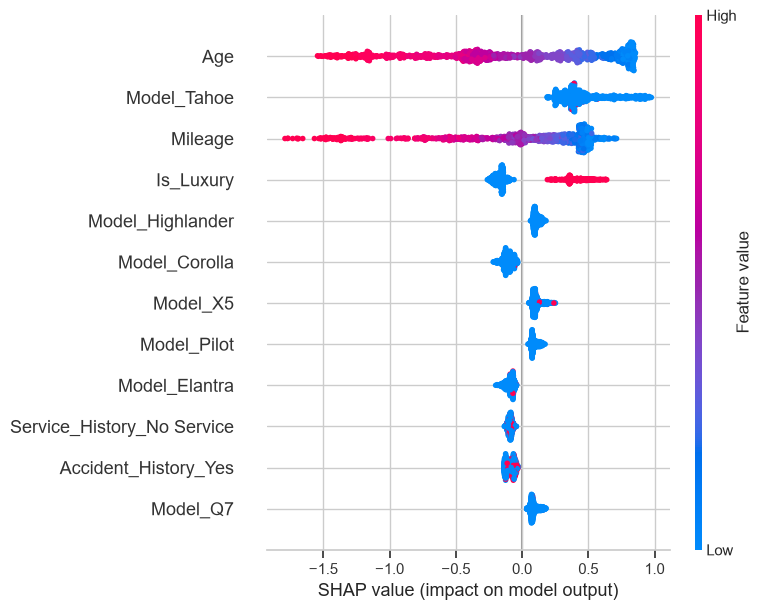

In [15]:
shap.summary_plot(sv.values, Xt_df, max_display=12)

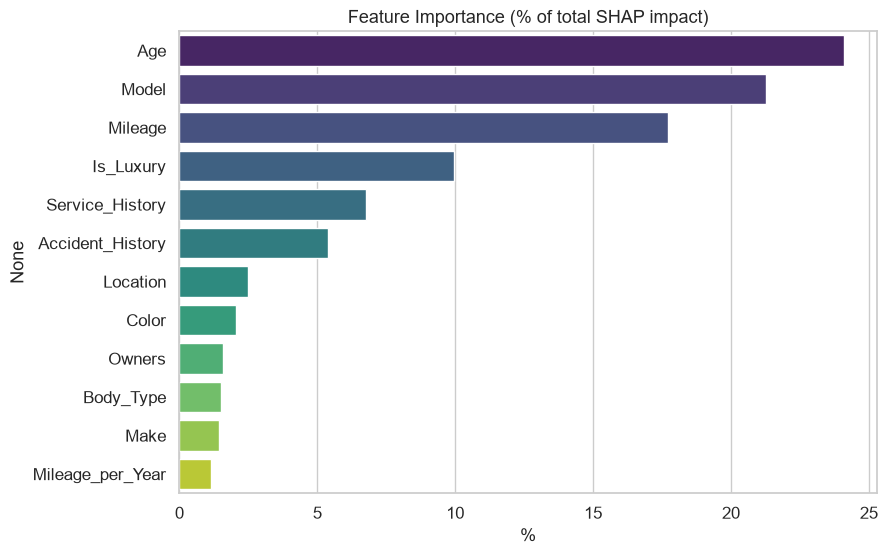

Age                 24.100000
Model               21.299999
Mileage             17.700001
Is_Luxury           10.000000
Service_History      6.800000
Accident_History     5.400000
Location             2.500000
Color                2.000000
Owners               1.600000
Body_Type            1.500000
Make                 1.500000
Mileage_per_Year     1.100000
dtype: float32

In [16]:
# One-hot splits e.g. Model into 40 columns. Sum them back per original feature.
groups = {}
for j, n in enumerate(names):
    base = next((c for c in cat_cols if n.startswith(c + "_")), n)
    groups.setdefault(base, []).append(j)

grouped = pd.DataFrame({b: sv.values[:, idx].sum(axis=1) for b, idx in groups.items()})
mean_abs = grouped.abs().mean()
importance = (mean_abs / mean_abs.sum() * 100).sort_values(ascending=False).head(12)

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index,
            palette="viridis", legend=False)
plt.title("Feature Importance (% of total SHAP impact)")
plt.xlabel("%")
plt.show()
importance.round(1)

Waterfall

Make                    Toyota
Model               Highlander
Age                         16
Mileage                 291129
Owners                       3
Accident_History       Unknown
Name: 550, dtype: object
Actual price: $ 500


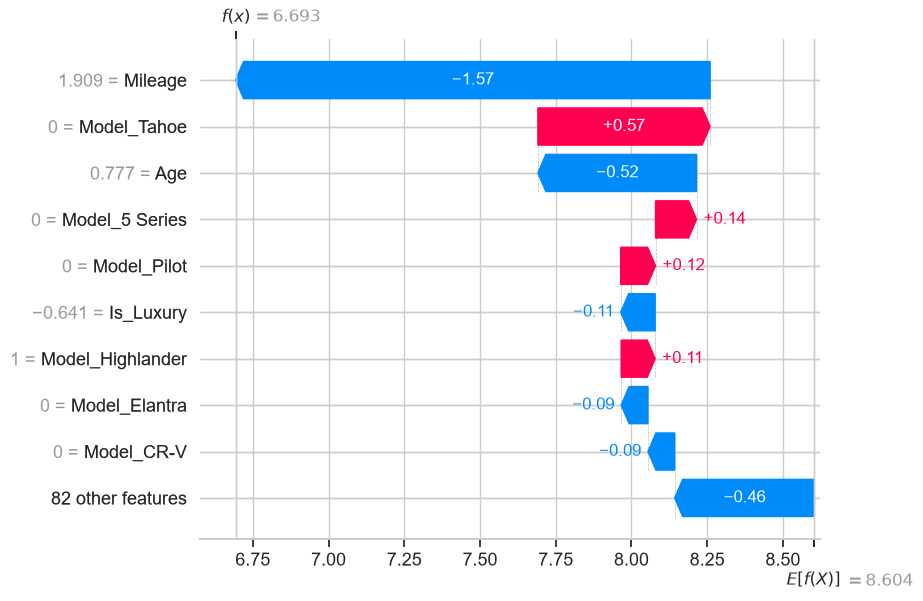

In [17]:
i = 0
print(X_test.iloc[i][["Make", "Model", "Age", "Mileage", "Owners", "Accident_History"]])
print("Actual price: $", round(np.expm1(y_test.iloc[i])))

shap.plots.waterfall(sv[i], max_display=10)

## ✅ Explainability Summary (SHAP)

| Feature | Share of total impact |
|---|---|
| Age | 25.4% |
| Model | 23.9% |
| Mileage | 15.6% |
| Is_Luxury | 9.8% |
| Service_History | 6.9% |
| Accident_History | 5.0% |

- The model relies on the same drivers found in EDA: **age, mileage, model and brand tier**.
- `Owners` (1.4%) adds little on top of `Age` and `Mileage`, since they carry overlapping information.
- Service and accident history have a real but smaller effect, while color and location contribute little.

# 🏁 Final Conclusions

## 📌 What we did
Analyzed **5,500 used cars** (18 columns), cleaned the data, explored price drivers with
Matplotlib, Seaborn, Plotly and Altair, engineered new features, and built a model that predicts price.

## 🔑 Key findings

| # | Finding |
|---|---|
| 1 | **Age is the strongest price driver** (correlation -0.80). Cars lose about **14% of their value per year**. |
| 2 | **22% of cars sit at a $500 price floor**: old, high-mileage cars with many owners. |
| 3 | **Accidents reduce the price by ~18-26%** when compared within the same age group (a naive comparison suggests 75%, which is inflated by age). |
| 4 | **Fuel type does not change value retention**: Electric and Hybrid look pricier only because they are newer. |
| 5 | **Brand tiers are clear** (Mercedes-Benz, BMW and Audi lead), yet all brands depreciate at similar rates (14.4%-16.2% per year). |
| 6 | **Service history matters** (~$2,000 gap), while **color and state show no significant effect**. |
| 7 | **XGBoost predicts price with R² = 0.984 and an average error of about $913.** |
| 8 | SHAP confirms the model relies on **age (25%), model (24%), mileage (16%) and luxury tier (10%)**. |

## ⚠️ Limitations
- The 22% of cars at the $500 floor limits how well low-end prices can be separated.
- Missing values (~15% in 9 columns) were imputed, which adds some uncertainty.
- Electric cars are few (145), so conclusions about them are less reliable.
- An R² this high suggests a regular pricing pattern; real-world listings usually contain more noise.

## 🚀 Next steps
- Tune hyperparameters (GridSearchCV or Optuna).
- Try LightGBM or CatBoost and compare.
- Deploy the model as a small web app (Streamlit) for price estimates.

In [18]:
import joblib

SAVE_PATH = r"D:\Codex Ai Course\Codex Training Projects\Python Project\model.joblib"

true_vals = np.expm1(y_test).values
pred_vals = preds["XGBoost"]

# Typical error per predicted-price range (used for the "likely range" in the app)
edges = [0, 5000, 15000, 30000, float("inf")]
pct_err = np.abs(true_vals - pred_vals) / true_vals * 100
bucket = pd.cut(pred_vals, bins=edges)
typical_error = (pd.Series(pct_err).groupby(bucket, observed=False)
                 .quantile(0.75).fillna(10).round(1).tolist())

# 'importance' comes from the SHAP cell; fall back to None if it wasn't run
try:
    imp = importance.round(1).to_dict()
except NameError:
    imp = None

bundle = {
    "model": fitted["XGBoost"],
    "features": X.columns.tolist(),
    "edges": edges,
    "typical_error_pct": typical_error,
    "metrics": results_df.to_dict("records"),
    "importance": imp,
}
joblib.dump(bundle, SAVE_PATH)
print("Saved to:", SAVE_PATH)
print("Typical error % per range:", typical_error)

Saved to: D:\Codex Ai Course\Codex Training Projects\Python Project\model.joblib
Typical error % per range: [27.5, 11.3, 8.3, 8.7]
